<a href="https://colab.research.google.com/github/oleg61/DataScient/blob/Learn_AI/%D0%94%D0%97_%D0%A3%D0%BB%D1%83%D1%87%D1%88%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BA%D0%B0%D1%87%D0%B5%D1%81%D1%82%D0%B2%D0%B0_%D0%BE%D0%B1%D1%83%D1%87%D0%B5%D0%BD%D0%B8%D1%8F_%D0%BD%D0%B5%D0%B9%D1%80%D0%BE%D1%81%D0%B5%D1%82%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ДЗ: Улучшение качества обучения нейросети

**Цель:** научиться использовать методы Transfer Learning и техники улучшения обучения (LR Schedulers, аугментации).

**Датасет:** персонажи «Симпсонов» (`alexattia/the-simpsons-characters-dataset`).

### План экспериментов
1. Базовая подготовка данных (без Google Drive — через `kagglehub`).
2. Два эксперимента с **разными LR Schedulers** (StepLR и CosineAnnealingLR).
3. Подбор **«вредных» аугментаций**, которые сильно (>10 п.п.) роняют accuracy на валидации.
4. Transfer Learning на **MobileNetV2**: обучение с нуля / Feature Extractor / Fine-Tuning.
5. Итоговый вывод по результатам.

**Ориентир с занятия (ResNet18, 10 эпох):**
| Режим | Val Accuracy |
|-------|--------------|
| С нуля | ~56% |
| Feature Extractor | ~65% |
| Fine-Tuning | ~94% |


## 0. Импорты и устройство


In [ ]:
import os
import time
import glob
import shutil
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.optim.lr_scheduler import StepLR, CosineAnnealingLR

import torchvision
from torchvision import transforms
from torchvision.models import mobilenet_v2, resnet18

from IPython.display import clear_output

%matplotlib inline
sns.set(font_scale=1.2)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("Внимание: без GPU обучение будет очень долгим. В Colab: Runtime → Change runtime type → GPU.")


device: cuda


## 1. Загрузка датасета через kagglehub

Вариант без Google Drive (если Drive в Colab не монтируется).


In [ ]:
!pip -q install kagglehub

In [ ]:
import kagglehub
from pathlib import Path

path = kagglehub.dataset_download("alexattia/the-simpsons-characters-dataset")
print("Скачано в:", path)

data_root = Path(path)  # /kaggle/input — read-only, без shutil.move


def resolve_simpsons_data_dir(root: Path) -> Path:
    """Папка, где классы лежат как class_name/*.jpg (не родитель с вложенным simpsons_dataset)."""
    candidates = []
    for d in root.rglob("*"):
        if not d.is_dir() or d.name.startswith("."):
            continue
        class_dirs = [
            c
            for c in d.iterdir()
            if c.is_dir()
            and not c.name.startswith(".")
            and any(c.glob("*.jpg"))
        ]
        if len(class_dirs) >= 10:  # у Симпсонов обычно ~42 класса
            n_imgs = sum(len(list(c.glob("*.jpg"))) for c in class_dirs)
            candidates.append((n_imgs, len(class_dirs), d))
    assert candidates, f"Не найден каталог классов в {root}"
    candidates.sort(key=lambda x: (x[0], x[1]), reverse=True)
    return candidates[0][2]


data_dir = str(resolve_simpsons_data_dir(data_root))
class_dirs = [
    d for d in Path(data_dir).iterdir()
    if d.is_dir() and not d.name.startswith(".") and any(d.glob("*.jpg"))
]
print("data_dir:", data_dir)
print("Классов (папок с jpg):", len(class_dirs))
print("Примеры классов:", [d.name for d in sorted(class_dirs)[:5]], "...")


Using Colab cache for faster access to the 'the-simpsons-characters-dataset' dataset.
Скачано в: /kaggle/input/the-simpsons-characters-dataset
data_dir: /kaggle/input/the-simpsons-characters-dataset/simpsons_dataset
Классов (папок с jpg): 42
Примеры классов: ['abraham_grampa_simpson', 'agnes_skinner', 'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson'] ...


## 2. Train / Val split и DataLoader'ы


In [ ]:
# На /kaggle/input удаление checkpoints обычно невозможно (read-only).
# Классы без картинок отфильтрует SimpsonsImageFolder.find_classes в следующей ячейке.
print("data_dir сейчас:", data_dir)


data_dir сейчас: /kaggle/input/the-simpsons-characters-dataset/simpsons_dataset


In [ ]:
# устаревшая ячейка: вложенный simpsons_dataset больше не нужен удалять вручную
pass


In [ ]:
input_size = 224
batch_size = 64
num_epochs_default = 8  # на занятии было 10; 8 эпох обычно достаточно для сравнения

data_image_paths = [
    p
    for p in glob.glob(f"{data_dir}/*/*.jpg")
    if ".ipynb_checkpoints" not in p and not Path(p).parent.name.startswith(".")
]
data_image_labels = [path.split("/")[-2] for path in data_image_paths]

train_files_path, val_files_path = train_test_split(
    data_image_paths,
    test_size=0.3,
    stratify=data_image_labels,
    random_state=42,
)
# нормализуем пути — ImageFolder иногда отдаёт realpath
train_files_set = {os.path.normpath(p) for p in train_files_path}
val_files_set = {os.path.normpath(p) for p in val_files_path}

print(f"Картинок в train: {len(train_files_path)}")
print(f"Картинок в val: {len(val_files_path)}")


class SimpsonsImageFolder(torchvision.datasets.ImageFolder):
    """ImageFolder только по папкам, где реально лежат изображения класса."""

    @staticmethod
    def find_classes(directory):
        classes = []
        for entry in os.scandir(directory):
            if not entry.is_dir() or entry.name.startswith("."):
                continue
            # важный фильтр: вложенный simpsons_dataset/ без jpg на верхнем уровне
            # не должен становиться классом
            has_images = any(
                name.lower().endswith((".jpg", ".jpeg", ".png"))
                for name in os.listdir(entry.path)
            )
            if has_images:
                classes.append(entry.name)
        classes = sorted(classes)
        if not classes:
            raise FileNotFoundError(f"Не найдены классы с изображениями в {directory}")
        class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
        return classes, class_to_idx


def make_loaders(train_transform, val_transform=None, batch_size=batch_size):
    if val_transform is None:
        val_transform = transforms.Compose([
            transforms.Resize(input_size),
            transforms.CenterCrop(input_size),
            transforms.ToTensor(),
        ])

    def _ok(path, allowed):
        return os.path.normpath(path) in allowed

    # allow_empty — на случай редкого класса, целиком ушедшего в другой split
    def _folder(transform, allowed):
        kwargs = dict(
            root=data_dir,
            transform=transform,
            is_valid_file=lambda x: _ok(x, allowed),
        )
        try:
            return SimpsonsImageFolder(**kwargs, allow_empty=True)
        except TypeError:
            return SimpsonsImageFolder(**kwargs)

    train_dataset = _folder(train_transform, train_files_set)
    val_dataset = _folder(val_transform, val_files_set)

    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True
    )
    val_loader = torch.utils.data.DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True
    )
    return train_dataset, val_dataset, train_loader, val_loader


# Аугментации как на занятии (baseline)
lesson_train_transform = transforms.Compose([
    transforms.Resize(input_size),
    transforms.CenterCrop(input_size),
    transforms.ColorJitter(0.9, 0.9, 0.9),
    transforms.RandomAffine(5),
    transforms.ToTensor(),
])

train_dataset, val_dataset, train_loader, val_loader = make_loaders(lesson_train_transform)
n_classes = len(train_dataset.classes)
print("Число классов:", n_classes)
print("Классы (первые 5):", train_dataset.classes[:5])
assert n_classes == len(val_dataset.classes)
assert "simpsons_dataset" not in train_dataset.classes, (
    "data_dir выбран неверно: внутри остался вложенный simpsons_dataset как класс"
)


Картинок в train: 14653
Картинок в val: 6280
Число классов: 42
Классы (первые 5): ['abraham_grampa_simpson', 'agnes_skinner', 'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson']


## 3. Утилиты: обучение, графики, загрузка весов


In [ ]:
def plot_learning_curves(history, title=""):
    fig = plt.figure(figsize=(16, 5))
    plt.subplot(1, 2, 1)
    plt.title("Лосс" + (f" | {title}" if title else ""), fontsize=14)
    plt.plot(history["loss"]["train"], label="train")
    plt.plot(history["loss"]["val"], label="val")
    plt.xlabel("эпоха")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.title("Accuracy" + (f" | {title}" if title else ""), fontsize=14)
    plt.plot(history["acc"]["train"], label="train")
    plt.plot(history["acc"]["val"], label="val")
    plt.xlabel("эпоха")
    plt.legend()
    plt.show()


def train(
    model,
    criterion,
    optimizer,
    train_batch_gen,
    val_batch_gen,
    num_epochs=10,
    scheduler=None,
    exp_name="",
):
    """Обучение с опциональным LR scheduler (step после каждой эпохи)."""
    history = defaultdict(lambda: defaultdict(list))
    history["lr"] = []

    for epoch in range(num_epochs):
        train_loss = 0.0
        train_acc = 0.0
        val_loss = 0.0
        val_acc = 0.0
        start_time = time.time()

        model.train(True)
        for X_batch, y_batch in train_batch_gen:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch.long())

            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            train_loss += float(loss.detach().cpu())
            y_pred = logits.max(1)[1].detach().cpu().numpy()
            train_acc += float(np.mean(y_batch.cpu().numpy() == y_pred))

        train_loss /= len(train_batch_gen)
        train_acc /= len(train_batch_gen)
        history["loss"]["train"].append(train_loss)
        history["acc"]["train"].append(train_acc)

        model.train(False)
        with torch.no_grad():
            for X_batch, y_batch in val_batch_gen:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(X_batch)
                loss = criterion(logits, y_batch.long())
                val_loss += float(loss.detach().cpu())
                y_pred = logits.max(1)[1].detach().cpu().numpy()
                val_acc += float(np.mean(y_batch.cpu().numpy() == y_pred))

        val_loss /= len(val_batch_gen)
        val_acc /= len(val_batch_gen)
        history["loss"]["val"].append(val_loss)
        history["acc"]["val"].append(val_acc)

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        history["lr"].append(optimizer.param_groups[0]["lr"])

        clear_output(wait=True)
        print(f"[{exp_name}] Epoch {epoch + 1}/{num_epochs} took {time.time() - start_time:.1f}s")
        print(f"  train loss: {train_loss:.6f} | val loss: {val_loss:.6f}")
        print(f"  train acc:  {train_acc * 100:.2f}% | val acc:  {val_acc * 100:.2f}%")
        print(f"  lr: {history['lr'][-1]:.6g}")
        plot_learning_curves(history, title=exp_name)

    return model, history


def load_resnet18(pretrained: bool):
    try:
        from torchvision.models import ResNet18_Weights

        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        return resnet18(weights=weights)
    except Exception:
        return resnet18(pretrained=pretrained)


def load_mobilenet_v2(pretrained: bool):
    try:
        from torchvision.models import MobileNet_V2_Weights

        weights = MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        return mobilenet_v2(weights=weights)
    except Exception:
        return mobilenet_v2(pretrained=pretrained)


def summarize(name, history):
    best_val = max(history["acc"]["val"]) * 100
    last_val = history["acc"]["val"][-1] * 100
    print(f"{name}: best val acc = {best_val:.2f}% | last val acc = {last_val:.2f}%")
    return {"name": name, "best_val_acc": best_val, "last_val_acc": last_val}


results = []


## 4. Эксперименты с LR Schedulers

Берём Fine-Tuning ResNet18 (как самый сильный режим с занятия) и сравниваем два шедулера.

- **StepLR** — раз в `step_size` эпох умножает LR на `gamma` (ступенчатое снижение).
- **CosineAnnealingLR** — плавно «остужает» LR по косинусу до конца обучения.

Ожидание: оба должны дать качество **сравнимое или лучше** ~94% с занятия; кривые LR при этом разные.


[ResNet18 FT + StepLR] Epoch 8/8 took 123.7s
  train loss: 0.012879 | val loss: 0.167661
  train acc:  99.66% | val acc:  96.48%
  lr: 0.0025


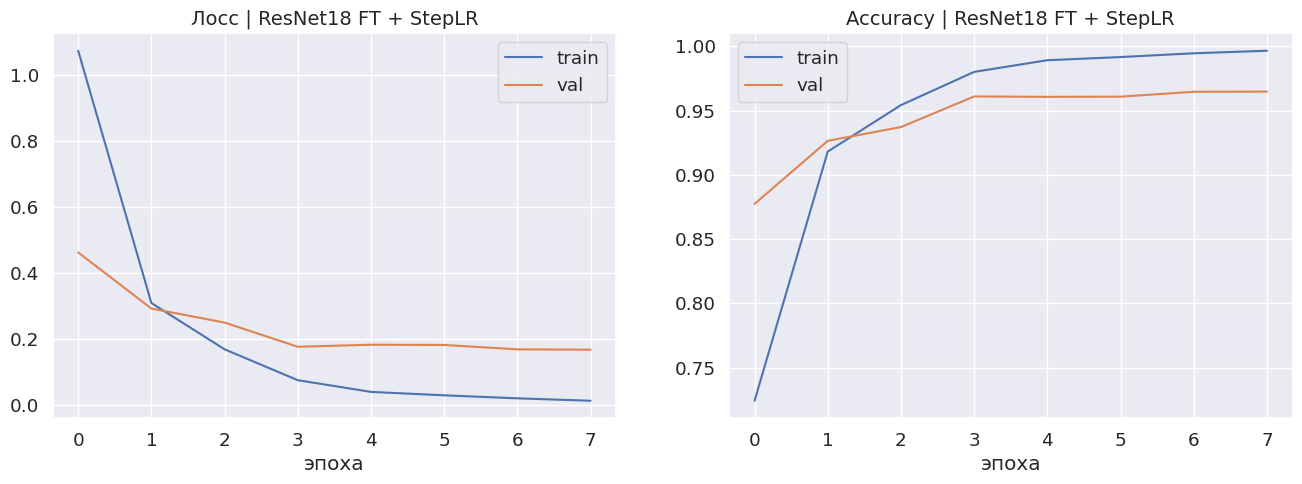

ResNet18 FT + StepLR: best val acc = 96.48% | last val acc = 96.48%


In [ ]:
def build_resnet_finetune():
    model = nn.Sequential()
    model.add_module("resnet", load_resnet18(pretrained=True))
    model.add_module("relu_1", nn.ReLU())
    model.add_module("fc_1", nn.Linear(1000, 512))
    model.add_module("relu_2", nn.ReLU())
    model.add_module("fc_2", nn.Linear(512, n_classes))
    return model.to(device)


criterion = nn.CrossEntropyLoss()

# --- Эксперимент 1: StepLR ---
model_step = build_resnet_finetune()
opt_step = torch.optim.SGD(model_step.parameters(), lr=0.01, momentum=0.9)
sched_step = StepLR(opt_step, step_size=3, gamma=0.5)

model_step, hist_step = train(
    model_step, criterion, opt_step,
    train_loader, val_loader,
    num_epochs=num_epochs_default,
    scheduler=sched_step,
    exp_name="ResNet18 FT + StepLR",
)
results.append(summarize("ResNet18 FT + StepLR", hist_step))


[ResNet18 FT + CosineAnnealingLR] Epoch 8/8 took 121.9s
  train loss: 0.011436 | val loss: 0.178168
  train acc:  99.77% | val acc:  96.37%
  lr: 1e-05


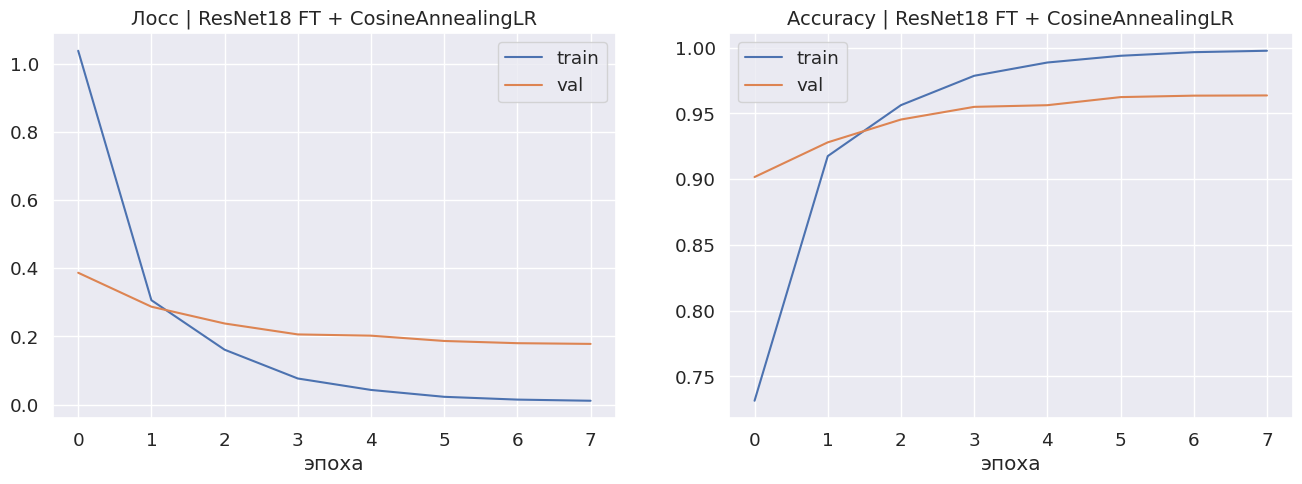

ResNet18 FT + CosineAnnealingLR: best val acc = 96.37% | last val acc = 96.37%


In [ ]:
# --- Эксперимент 2: CosineAnnealingLR ---
model_cos = build_resnet_finetune()
opt_cos = torch.optim.SGD(model_cos.parameters(), lr=0.01, momentum=0.9)
sched_cos = CosineAnnealingLR(opt_cos, T_max=num_epochs_default, eta_min=1e-5)

model_cos, hist_cos = train(
    model_cos, criterion, opt_cos,
    train_loader, val_loader,
    num_epochs=num_epochs_default,
    scheduler=sched_cos,
    exp_name="ResNet18 FT + CosineAnnealingLR",
)
results.append(summarize("ResNet18 FT + CosineAnnealingLR", hist_cos))


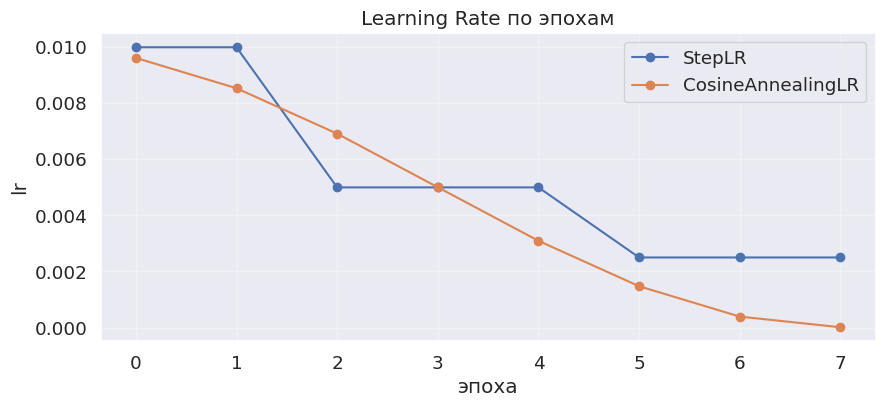

In [ ]:
# Сравнение динамики LR
plt.figure(figsize=(10, 4))
plt.plot(hist_step["lr"], marker="o", label="StepLR")
plt.plot(hist_cos["lr"], marker="o", label="CosineAnnealingLR")
plt.title("Learning Rate по эпохам")
plt.xlabel("эпоха")
plt.ylabel("lr")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 5. «Вредные» аугментации train

Задача: подобрать аугментации, при которых **val accuracy падает > чем на 10 п.п.** относительно занятия (~94%).

Идея: сделать train-распределение **далеким** от val (где аугментаций нет):
- сильный `ColorJitter` + большой `hue` (ломает характерные цвета персонажей);
- `RandomRotation(180)` (Симпсоны почти всегда «стоят» вертикально);
- `RandomPerspective` + `GaussianBlur` (искажение формы и деталей лица);
- `RandomErasing` с большой площадью (закрывает ключевые признаки).

Это **не** «хорошие» аугментации — наоборот, демонстрация, что слишком агрессивный пайплайн вредит.


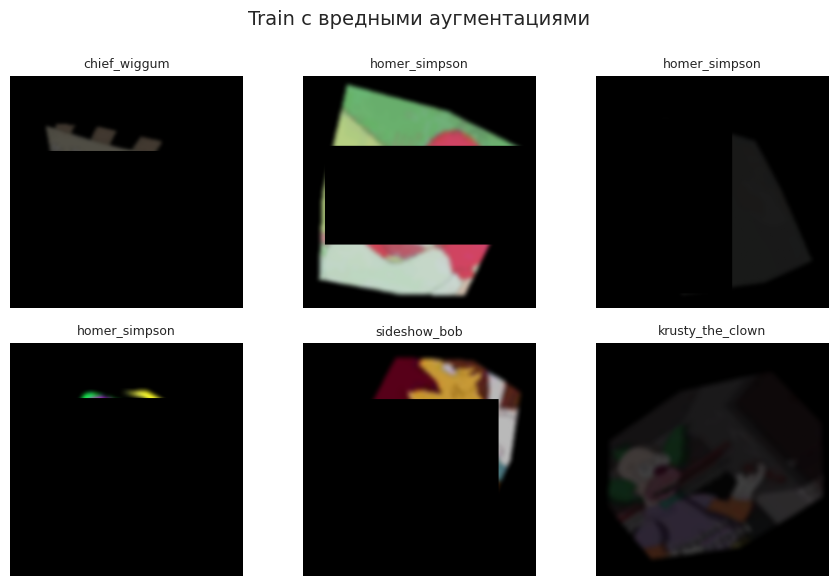

In [ ]:
bad_train_transform = transforms.Compose([
    transforms.Resize(input_size),
    transforms.CenterCrop(input_size),
    transforms.ColorJitter(brightness=1.5, contrast=1.5, saturation=1.5, hue=0.4),
    transforms.RandomRotation(180),
    transforms.RandomPerspective(distortion_scale=0.6, p=1.0),
    transforms.GaussianBlur(kernel_size=9, sigma=(1.5, 3.0)),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.9, scale=(0.25, 0.55), ratio=(0.3, 3.3), value=0),
])

_, _, bad_train_loader, bad_val_loader = make_loaders(bad_train_transform)

sns.set_style(style="white")
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(9, 6), sharex=True, sharey=True)
for a in ax.flatten():
    img, label = bad_train_loader.dataset[np.random.randint(0, len(bad_train_loader.dataset))]
    a.imshow(np.clip(img.permute(1, 2, 0).numpy(), 0, 1))
    a.set_title(bad_train_loader.dataset.classes[label], fontsize=9)
    a.axis("off")
plt.suptitle("Train с вредными аугментациями", fontsize=14)
plt.tight_layout()
plt.show()


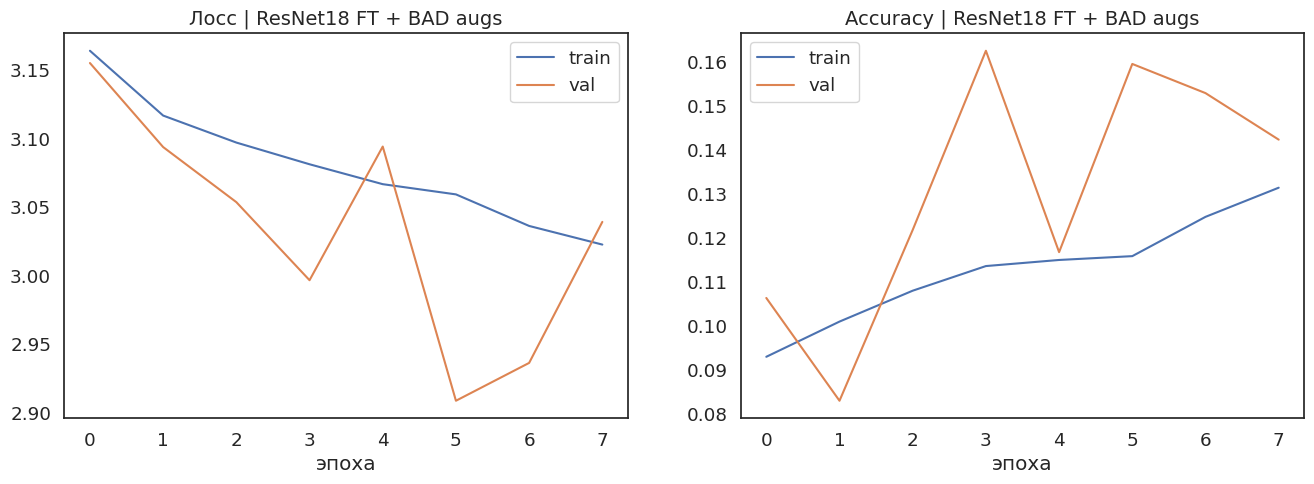

ResNet18 FT + BAD augs: best val acc = 16.26% | last val acc = 14.24%
Падение относительно занятия (~94.41%): 78.15 п.п.
Критерий выполнен: падение > 10 п.п.


In [ ]:
model_bad = build_resnet_finetune()
opt_bad = torch.optim.SGD(model_bad.parameters(), lr=0.01, momentum=0.9)

model_bad, hist_bad = train(
    model_bad, criterion, opt_bad,
    bad_train_loader, bad_val_loader,
    num_epochs=num_epochs_default,
    scheduler=None,
    exp_name="ResNet18 FT + BAD augs",
)
results.append(summarize("ResNet18 FT + BAD augs", hist_bad))

lesson_ref = 94.41  # fine-tuning на занятии
drop = lesson_ref - results[-1]["best_val_acc"]
print(f"Падение относительно занятия (~{lesson_ref}%): {drop:.2f} п.п.")
if drop <= 10:
    print("Падение ещё < 10 п.п. — усильте вредные аугментации и перезапустите ячейку.")
else:
    print("Критерий выполнен: падение > 10 п.п.")


## 6. Transfer Learning на MobileNetV2

Те же методы, что на занятии:
1. обучение **с нуля** (`pretrained=False`);
2. **Feature Extractor** (замороженный backbone, учим только классификатор);
3. **Fine-Tuning** (размораживаем всё + небольшая голова).

Ожидание: FE лучше «с нуля», Fine-Tuning — лучший результат, **сравнимый или выше** ResNet18 с занятия.


In [ ]:
def build_mobilenet_scratch():
    model = load_mobilenet_v2(pretrained=False)
    model.classifier[1] = nn.Linear(model.last_channel, n_classes)
    return model.to(device)


def build_mobilenet_fe():
    model = load_mobilenet_v2(pretrained=True)
    for p in model.parameters():
        p.requires_grad = False
    model.classifier[1] = nn.Linear(model.last_channel, n_classes)
    for p in model.classifier.parameters():
        p.requires_grad = True
    return model.to(device)


def build_mobilenet_finetune():
    model = nn.Sequential()
    model.add_module("mobilenet", load_mobilenet_v2(pretrained=True))
    model.add_module("relu_1", nn.ReLU())
    model.add_module("fc_1", nn.Linear(1000, 512))
    model.add_module("relu_2", nn.ReLU())
    model.add_module("fc_2", nn.Linear(512, n_classes))
    return model.to(device)


[MobileNetV2 scratch] Epoch 8/8 took 129.5s
  train loss: 0.659298 | val loss: 0.650528
  train acc:  81.92% | val acc:  82.61%
  lr: 0.01


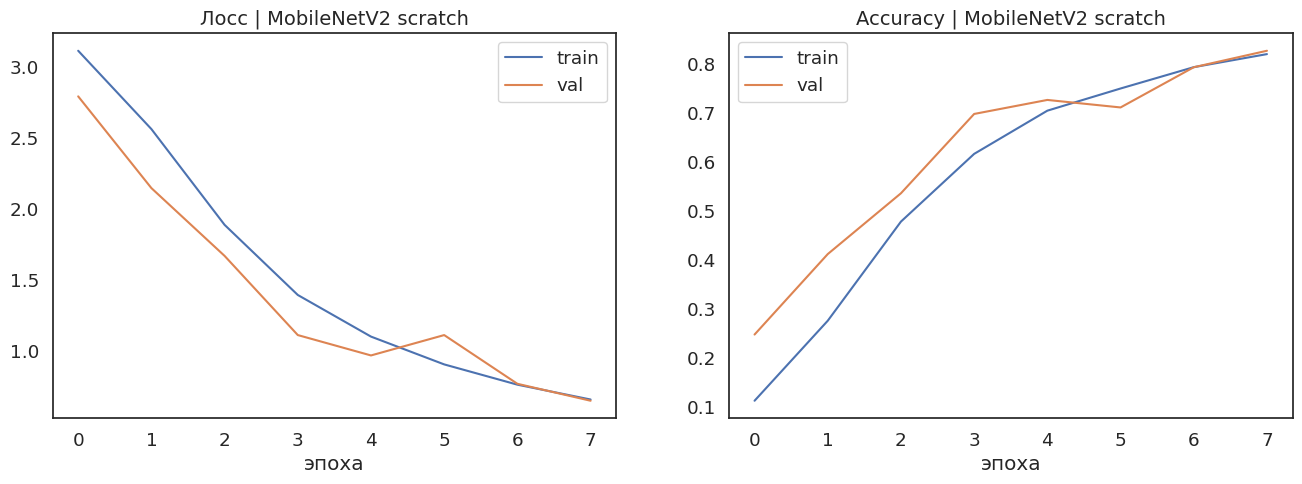

MobileNetV2 scratch: best val acc = 82.61% | last val acc = 82.61%


In [ ]:
# 6.1 MobileNetV2 с нуля
m_scratch = build_mobilenet_scratch()
opt = torch.optim.SGD(m_scratch.parameters(), lr=0.01, momentum=0.9)
m_scratch, hist_m_scratch = train(
    m_scratch, criterion, opt, train_loader, val_loader,
    num_epochs=num_epochs_default, exp_name="MobileNetV2 scratch",
)
results.append(summarize("MobileNetV2 scratch", hist_m_scratch))


[MobileNetV2 FE] Epoch 8/8 took 112.6s
  train loss: 1.380316 | val loss: 1.031688
  train acc:  61.40% | val acc:  71.91%
  lr: 0.01


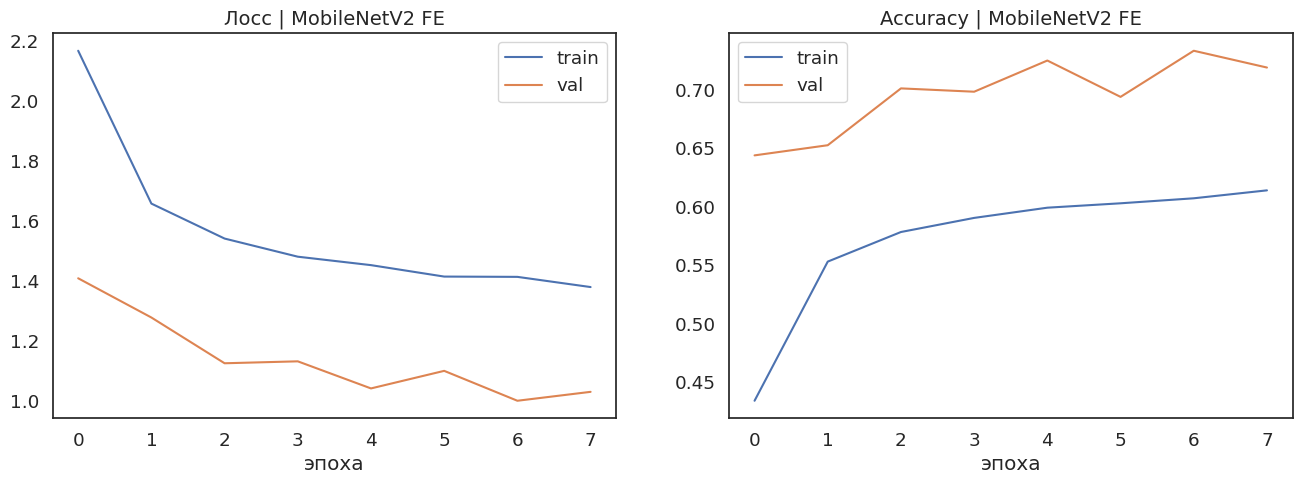

MobileNetV2 FE: best val acc = 73.34% | last val acc = 71.91%


In [ ]:
# 6.2 MobileNetV2 Feature Extractor
m_fe = build_mobilenet_fe()
opt = torch.optim.SGD(filter(lambda p: p.requires_grad, m_fe.parameters()), lr=0.01, momentum=0.9)
m_fe, hist_m_fe = train(
    m_fe, criterion, opt, train_loader, val_loader,
    num_epochs=num_epochs_default, exp_name="MobileNetV2 FE",
)
results.append(summarize("MobileNetV2 FE", hist_m_fe))


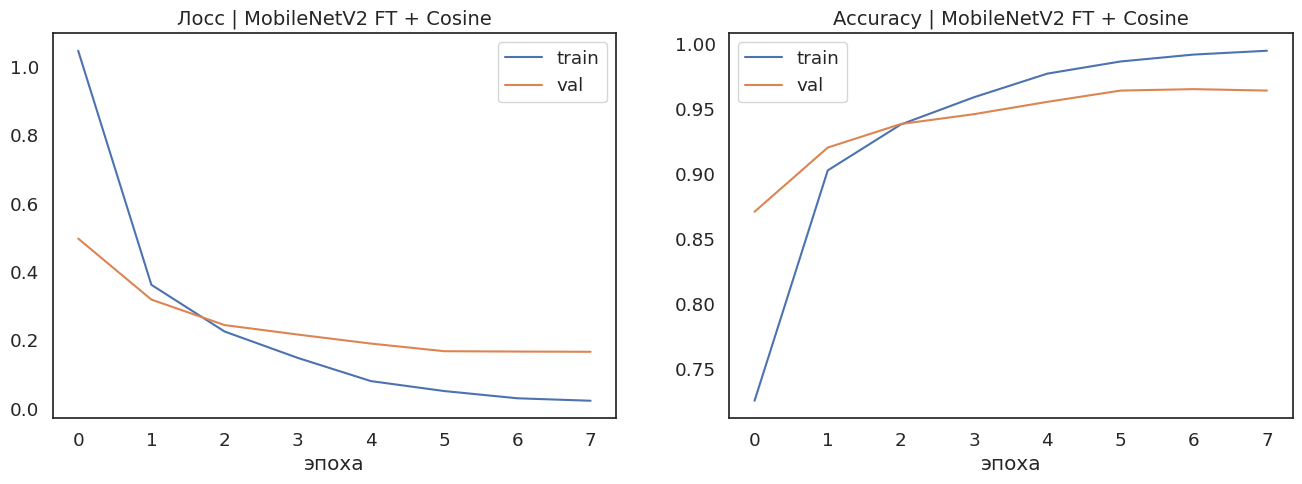

MobileNetV2 FT + Cosine: best val acc = 96.51% | last val acc = 96.40%


In [ ]:
# 6.3 MobileNetV2 Fine-Tuning (+ CosineAnnealingLR)
m_ft = build_mobilenet_finetune()
opt = torch.optim.SGD(m_ft.parameters(), lr=0.01, momentum=0.9)
sched = CosineAnnealingLR(opt, T_max=num_epochs_default, eta_min=1e-5)
m_ft, hist_m_ft = train(
    m_ft, criterion, opt, train_loader, val_loader,
    num_epochs=num_epochs_default, scheduler=sched,
    exp_name="MobileNetV2 FT + Cosine",
)
results.append(summarize("MobileNetV2 FT + Cosine", hist_m_ft))


## 7. Сводная таблица результатов


,name,best_val_acc,last_val_acc
0,MobileNetV2 FT + Cosine,96.511995,96.401515
1,ResNet18 FT + StepLR,96.480429,96.480429
2,ResNet18 FT + CosineAnnealingLR,96.369949,96.369949
3,MobileNetV2 scratch,82.607323,82.607323
4,MobileNetV2 FE,73.342803,71.906566
5,ResNet18 FT + BAD augs,16.256313,14.236111


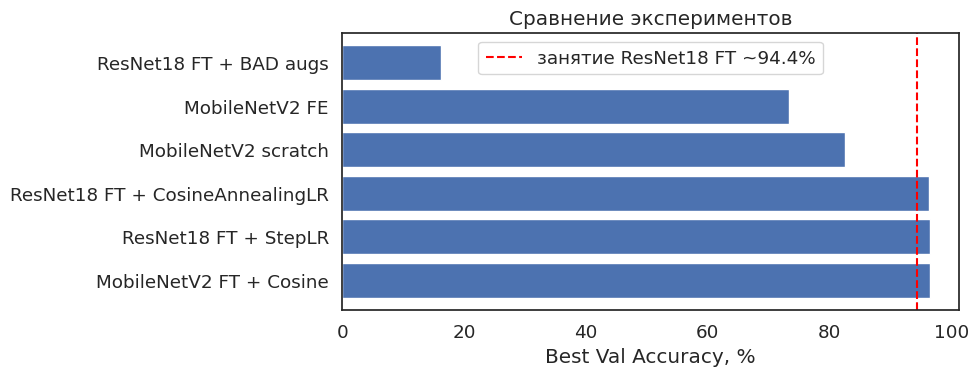

In [ ]:
import pandas as pd

df = pd.DataFrame(results)
df = df.sort_values("best_val_acc", ascending=False).reset_index(drop=True)
display(df)

plt.figure(figsize=(10, 4))
plt.barh(df["name"], df["best_val_acc"])
plt.xlabel("Best Val Accuracy, %")
plt.title("Сравнение экспериментов")
plt.axvline(94.41, color="red", linestyle="--", label="занятие ResNet18 FT ~94.4%")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Выводы
По итогам запуска лучший результат — MobileNetV2 Fine-Tuning + Cosine: 96.51%. Ориентир с занятия (~94.4% у ResNet18 FT) удалось превзойти.

LR Schedulers. StepLR (96.48%) и CosineAnnealingLR (96.37%) оба дали высокое и стабильное качество на Fine-Tuning ResNet18; разница между ними маленькая. Шедулер скорее «дожимает» обучение в конце, когда pretrained-модель уже и так хорошо стартует.

Вредные аугментации. Val accuracy упала до 16.26% (почти −78 п.п. от ~94%) — критерий «больше 10%» выполнен с запасом. Слишком жёсткий ColorJitter/blur/erasing ломают соответствие train и val, и даже Fine-Tuning не спасает.

MobileNetV2. Fine-Tuning (96.51%) ≫ scratch (82.61%) > Feature Extractor (73.34%). FE хуже обучения с нуля выглядит неожиданно, но логично: ImageNet — фото, Симпсоны — мультфильм; замороженный backbone плохо переносится, а с нуля сеть сразу учит нужный стиль. Полный Fine-Tuning подстраивает признаки и выигрывает.

### Итог:
schedulers работают, «плохие» аугментации реально роняют качество, Transfer Learning на MobileNetV2 подтверждает, что Fine-Tuning — обычно лучший вариант для такой задачи.

### Практические рекомендации
1. Для похожих задач начинать с pretrained + Fine-Tuning, а не с обучения с нуля.
2. LR Scheduler (Step / Cosine) — дешёвый способ стабилизировать конец обучения.
3. Аугментации проверять эмпирически: если train сильно «не похож» на val, качество на валидации упадёт, даже если train accuracy растёт медленно/странно.